This notebook loads and visualises the outputs from the three experiment families in this repo:

1. **Batch benchmark** (`batch_experiments.py`) — classical train/test evaluation on Kaggle Fraud and UNSW-NB15.
2. **Online benchmark** (`online_experiments.py`) — one-pass, temporal evaluation on cybersecurity and MIT-BIH.
3. **Continual-learning benchmark** (`continual_experiments.py`) — Task-IL, Domain-IL and Class-IL scenarios on MNIST.

Run the experiments from the command line with:
```bash
python main.py --experiment all
```
or re-run the cells below that call the runner functions.

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")))

from online_experiments import (
    run_online_benchmark,
    ensure_reproducibility,
)
from batch_experiments import run_batch_benchmark
from continual_experiments import run_continual_experiments
from algos import warmup_jit

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

DATA_DIR = os.path.join(os.getcwd(), 'data')
RESULTS_DIR = os.path.join(os.getcwd(), 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

print('Imports complete.')

Imports complete.


## Optional: re-run all experiments

The cells below call the same functions used by `main.py`. They can be slow (minutes to tens of minutes depending on the machine), so by default we skip execution and load the saved CSVs in the next section. Set `RUN_EXPERIMENTS = True` to regenerate everything.

In [2]:
RUN_EXPERIMENTS = False   # Set to True to regenerate result CSVs
SEED = 42
ensure_reproducibility(SEED)
warmup_jit()

Random seed set to 42
Warming up Numba JIT kernels...
JIT warm-up complete.


In [3]:
if RUN_EXPERIMENTS:
    print('Running batch benchmark...')
    run_batch_benchmark(DATA_DIR, output_dir=RESULTS_DIR)
else:
    print('Skipping batch benchmark; loading existing CSV.')

Skipping batch benchmark; loading existing CSV.


In [4]:
if RUN_EXPERIMENTS:
    print('Running online benchmark...')
    run_online_benchmark(DATA_DIR, output_dir=RESULTS_DIR)
else:
    print('Skipping online benchmark; loading existing CSV.')

Skipping online benchmark; loading existing CSV.


In [5]:
if RUN_EXPERIMENTS:
    print('Running continual-learning experiments...')
    run_continual_experiments(DATA_DIR, output_dir=RESULTS_DIR)
else:
    print('Skipping continual-learning experiments; loading existing CSV.')

Skipping continual-learning experiments; loading existing CSV.


## Load result files

In [6]:
batch_df = pd.read_csv(os.path.join(RESULTS_DIR, 'batch_benchmark_results.csv'))
online_df = pd.read_csv(os.path.join(RESULTS_DIR, 'online_benchmark_results.csv'))
continual_df = pd.read_csv(os.path.join(RESULTS_DIR, 'continual_learning_summary.csv'), header=[0, 1, 2])

print('Batch results shape:', batch_df.shape)
print('Online results shape:', online_df.shape)
print('Continual results shape:', continual_df.shape)

Batch results shape: (105, 7)
Online results shape: (91, 7)
Continual results shape: (29, 33)


## 1. Batch benchmark results

Classical train/test evaluation. Higher F1 is better.

In [7]:
batch_df

,Dataset,Algorithm,Precision,Recall,F1,FNR,FPR
0,CreditFraud_kaggle,AROW,0.0059,0.7200,0.0117,0.2800,0.1598
1,Crypto_desktop,AROW,0.0046,0.2294,0.0090,0.7706,0.4289
2,Crypto_smartphone,AROW,0.0011,0.1829,0.0023,0.8171,0.3605
3,MITBIH_Arrhythmia,AROW,0.5072,0.7326,0.5994,0.2674,0.1483
4,NonEnc_desktop,AROW,0.3252,0.8303,0.4673,0.1697,0.5409
...,...,...,...,...,...,...,...
100,P2P_desktop,SCW,0.1642,1.0000,0.2822,0.0000,1.0000
101,P2P_smartphone,SCW,0.1070,1.0000,0.1934,0.0000,1.0000
102,Phishing_desktop,SCW,0.1712,1.0000,0.2923,0.0000,1.0000
103,Phishing_smartphone,SCW,0.2086,1.0000,0.3452,0.0000,1.0000


In [8]:
batch_df[batch_df['Dataset'].isin(['UNSW_NB15','CreditFraud_kaggle'])].reset_index(drop=True).sort_values(by=['Dataset', 'F1'], ascending=[True, False])

,Dataset,Algorithm,Precision,Recall,F1,FNR,FPR
4,CreditFraud_kaggle,OGC,0.7215,0.7600,0.7403,0.2400,0.0004
6,CreditFraud_kaggle,PA,0.4130,0.7600,0.5352,0.2400,0.0014
8,CreditFraud_kaggle,Perceptron,0.1667,0.6933,0.2687,0.3067,0.0046
0,CreditFraud_kaggle,AROW,0.0059,0.7200,0.0117,0.2800,0.1598
2,CreditFraud_kaggle,AdaRDA,0.0013,1.0000,0.0026,0.0000,1.0000
10,CreditFraud_kaggle,RDA,0.0013,1.0000,0.0026,0.0000,1.0000
12,CreditFraud_kaggle,SCW,0.0013,1.0000,0.0026,0.0000,1.0000
5,UNSW_NB15,OGC,0.9980,0.9987,0.9984,0.0013,0.0025
9,UNSW_NB15,Perceptron,0.9973,0.9984,0.9978,0.0016,0.0033
7,UNSW_NB15,PA,0.9940,0.9972,0.9956,0.0028,0.0074


## 2. Online results

Single-pass, temporally-ordered evaluation. Higher F1 is better.

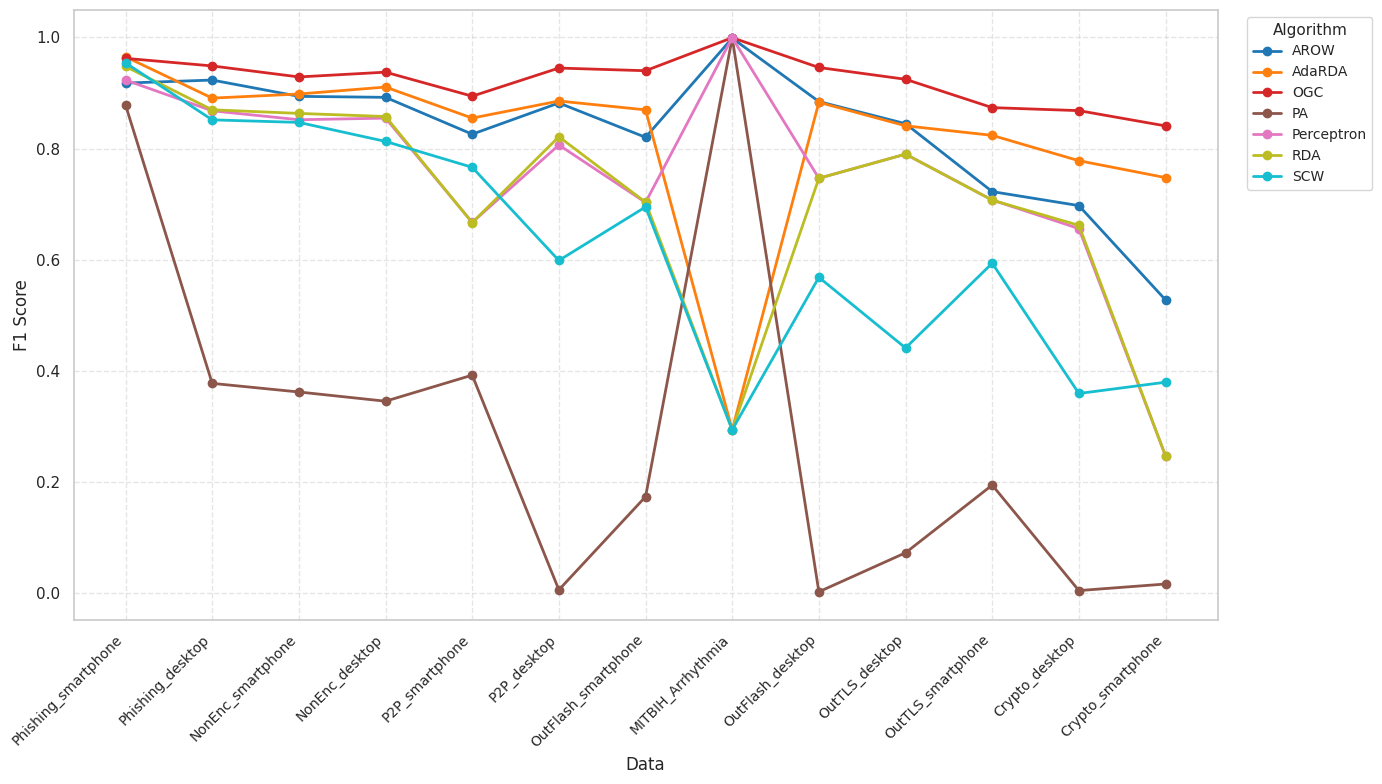

In [9]:
df = online_df

pivot_df = df.pivot(index='Dataset', columns='Algorithm', values='F1')

pivot_df = pivot_df.reindex(pivot_df.mean(axis=1).sort_values(ascending=False).index)


fig, ax = plt.subplots(figsize=(14, 8))
pivot_df.plot(kind='line', marker='o', ax=ax, colormap='tab10', linewidth=2)


#ax.set_title('F1 Score: Each Algorithm Denotes Its Own Line', fontsize=14, pad=15)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_xlabel('Data', fontsize=12)
ax.set_xticks(range(len(pivot_df.index)))
ax.set_xticklabels(pivot_df.index, rotation=45, ha='right', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

# Place legend cleanly outside the plot canvas
ax.legend(title='Algorithm', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

## 3. Continual-learning results

Three incremental scenarios:
* **Task-IL** — task identity known at test time.
* **Domain-IL** — fixed label space, distribution shifts across chunks.
* **Class-IL** — label space grows; single shared predictor.

Reported metrics include `FwdF1` (forward transfer F1), `M_T` (forgetting / performance drop), and `MacroF1` (for multi-class MNIST).

In [10]:
# The CSV has a MultiIndex header; show the raw frame for reference
# display(continual_df.head(10))

# Identify the row-key columns and the value columns
dataset_col = ('Scenario', 'Algorithm', 'Dataset')
metric_col = ('Unnamed: 1_level_0', 'Unnamed: 1_level_1', 'Metric')
value_cols = [c for c in continual_df.columns if c not in (dataset_col, metric_col)]

def parse_mean(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if chr(177) in s:   # plus-minus character
        return float(s.split(chr(177))[0].strip())
    try:
        return float(s)
    except ValueError:
        return np.nan

continual_numeric = continual_df.copy()
for c in value_cols:
    continual_numeric[c] = continual_df[c].apply(parse_mean)


In [11]:
# Focus on MNIST under all three continual scenarios
mnist_rows = continual_numeric[continual_numeric[dataset_col] == 'MNIST']

task_il_cols = [c for c in value_cols if c[0] == 'Task-IL']
domain_il_cols = [c for c in value_cols if c[0] == 'Domain-IL']
class_il_cols = [c for c in value_cols if c[0] == 'Class-IL']

print('MNIST Task-IL MacroF1:')
task_il_macro = mnist_rows[mnist_rows[metric_col] == 'MacroF1'][task_il_cols]
task_il_macro.columns = task_il_macro.columns.droplevel(2)
display(task_il_macro.round(3))

print('MNIST Domain-IL FwdMacroF1:')
domain_il_macro = mnist_rows[mnist_rows[metric_col] == 'FwdMacroF1'][domain_il_cols]
domain_il_macro.columns = domain_il_macro.columns.droplevel(2)
display(domain_il_macro.round(3))

print('MNIST Class-IL MacroF1:')
class_il_macro = mnist_rows[mnist_rows[metric_col] == 'MacroF1'][class_il_cols]
class_il_macro.columns = class_il_macro.columns.droplevel(2)
display(class_il_macro.round(3))

MNIST Task-IL MacroF1:


Task-IL                                                   
     AROW AdaRDA    OGC     PA Perceptron    RDA   SCW 0.958
8   0.958  0.963  0.952  0.953      0.958  0.965  0.96   NaN

MNIST Domain-IL FwdMacroF1:


Domain-IL                                                   
       AROW AdaRDA    OGC     PA Perceptron   RDA    SCW 0.853
6     0.853  0.812  0.782  0.809      0.837  0.79  0.866   NaN

MNIST Class-IL MacroF1:


Class-IL                                                   
      AROW AdaRDA    OGC     PA Perceptron    RDA   SCW 0.958
8    0.958  0.946  0.952  0.953      0.958  0.948  0.96   NaN